# 夸父金融 D2：历史布局与位序诊断

本附件只读取已经完成的 13 项真实实验，不提交新任务、不使用密钥、不修改五类金融结果。
核心结论：**保留剩余 7 项额度，暂不提交默认映射的 one-hot。**
物理位集合、有序测量映射、服务端 counts 字符串排序是三个不同概念。
以下候选分数只是相对无噪声理想分布的诊断，不能将最佳拟合当成真实位序。


In [1]:
import json, hashlib
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()
while not (root / "quantumbridge/finance").is_dir() and root != root.parent:
    root = root.parent
base = root / "output/finance-hardware/diagnostics/d2"
load = lambda name: json.loads((base / name).read_text())
integrity = load("d2_readonly_audit.json")
assert integrity["total_tasks"] == 13 and integrity["new_submissions"] == 0
assert all(hashlib.sha256((root / name).read_bytes()).hexdigest() == digest
           for name, digest in integrity["file_hashes"].items())
print("13项实验及原始证据复核通过，无新云任务；剩余额度:", integrity["remaining_tasks"])
layout = load("physical_layout_matrix.json")


13项实验及原始证据复核通过，无新云任务；剩余额度: 7


## 1. 真实物理布局矩阵

从已保存 compiled QASM 和 QLISP 重新解析，不把先前报告中的表格硬编码为事实。
层深采用每门单位时长的逻辑层数，不是脉冲时间，也不是设备保真度。


In [2]:
display(pd.DataFrame([{"experiment": key, "task": value["task_id"],
    "physical_set": sorted(value["native_compiled"]["active_physical_qubits"]),
    "ordered_c_to_physical": value["ordered_measurement_mapping"],
    "gates": value["gate_profile"]["unitary_operation_count"],
    "layer_depth": value["gate_profile"]["logical_layer_depth"],
    "created": value["fields"]["created"]["value"]} for key, value in layout.items()]))


,experiment,task,physical_set,ordered_c_to_physical,gates,layer_depth,created
0,calibration/bit-order,2610231235264038840,"[4, 11]","[11, 4]",1,1,2026-10-23 12:35:27.127830
1,allocation/qaoa,2610231235383826369,"[3, 4, 10, 11]","[10, 3, 4, 11]",57,38,2026-10-23 12:35:39.857208
2,risk/base,2610231235440801552,"[3, 4, 10]","[10, 3, 4]",44,33,2026-10-23 12:35:44.683365
3,risk/stress,2610231235484838251,"[3, 4, 10]","[10, 3, 4]",44,33,2026-10-23 12:35:49.205290
4,derivatives/risk_neutral_paths,2610231235566974565,"[4, 5, 11]","[11, 4, 5]",3,1,2026-10-23 12:35:57.285174
5,constraints/qaoa,2610231236018836200,"[3, 4, 10, 11]","[10, 3, 4, 11]",57,38,2026-10-23 12:36:02.725119
6,correlation/positive_correlation,2610231236118773106,"[3, 4, 10, 11]","[10, 3, 11, 4]",130,84,2026-10-23 12:36:12.567061
7,correlation/negative_correlation,2610231236189351427,"[3, 4, 10, 11]","[10, 3, 11, 4]",130,84,2026-10-23 12:36:19.519742
8,correlation/time_sampling,2610231236333069511,"[4, 5, 11]","[11, 4, 5]",3,1,2026-10-23 12:36:33.842887
9,diagnostic/3q-zero,2610231309374778530,"[4, 5, 11]","[11, 4, 5]",0,0,2026-10-23 13:09:38.171629


## 2. 候选 counts 位序：分数不等于证明

对宽度 n 枚举所有 n! 种字符串解释，保留 identity、reverse 及按物理编号排序的候选标记。
计算规范化 counts、TVD、边缘偏差和 multinomial log-likelihood（省略共同组合常数）。
如果观测结果在理想分布中的概率为零，严格无噪声似然为零，log 为负无穷；JSON 中记为 None，
并显示 `positive_counts_at_zero_ideal_probability=True`，不添加事后伪计数。
全零、全一的候选似然完全相同。真实噪声未知，金融结果的最好拟合也不能证明位序。


In [3]:
hypotheses = load("count_order_hypotheses.json")
rows = []
for key, value in hypotheses.items():
    assert value["status"] == "AMBIGUOUS" and value["selected_permutation"] is None
    if key.startswith("diagnostic/"):
        assert len({item["noiseless_multinomial_log_likelihood_up_to_constant"] for item in value["candidates"]}) == 1
    for item in value["candidates"]:
        if item["aliases"]:
            rows.append({"experiment": key, "interpretation": ", ".join(item["aliases"]),
                         "TVD": item["TVD"], "log_likelihood": item["noiseless_multinomial_log_likelihood_up_to_constant"],
                         "ideal_zero_mass_conflict": item["positive_counts_at_zero_ideal_probability"],
                         "marginal_deviation": item["marginal_deviation"]})
display(pd.DataFrame(rows))


,experiment,interpretation,TVD,log_likelihood,ideal_zero_mass_conflict,marginal_deviation
0,calibration/bit-order,identity,0.989258,NaN,True,"[-0.845703125, 0.9521484375]"
1,calibration/bit-order,"reverse, ascending_physical_register_HYPOTHESIS",0.191406,NaN,True,"[-0.0478515625, 0.154296875]"
2,allocation/qaoa,identity,0.366456,-3211.778989,False,"[0.032178954309255256, -0.03717861359447079, -..."
3,allocation/qaoa,ascending_physical_register_HYPOTHESIS,0.366456,-3212.123202,False,"[-0.03618042069074477, 0.03313388640552921, -0..."
4,allocation/qaoa,reverse,0.366456,-3212.193807,False,"[-0.011766358190744744, -0.03522548859447079, ..."
5,risk/base,identity,0.434414,-2534.095133,False,"[0.4344140624970904, 0.07894531256335811, -0.0..."
6,risk/base,ascending_physical_register_HYPOTHESIS,0.333281,-2153.908998,False,"[0.1277734374970904, 0.30941406256335807, -0.0..."
7,risk/base,reverse,0.253281,-2033.354150,False,"[0.1277734374970904, 0.07894531256335811, 0.21..."
8,risk/stress,identity,0.403984,-2386.920061,False,"[0.40398437500382023, 0.07207031250327334, -0...."
9,risk/stress,ascending_physical_register_HYPOTHESIS,0.283984,-2077.901320,False,"[0.038750000003820194, 0.28398437500327334, 0...."


## 3. 历史业务与诊断配对的可比性

36 组配对同时检查物理集合、有序测量、门族、层深、任务时间、编译选项与校准 ID。
同布局的 Pricing／History 与 D1 3q 可以条件性比较，但时间间隔及缺失 calibration ID
意味着仍未证明误差可迁移。D1 4q 与历史 4q 物理集合不同，不能直接套用边缘错误率。


In [4]:
pairs = load("historical_task_pairing.json")
display(pd.DataFrame([{"pair": name, "set_matches": value["physical_set_matches"],
    "ordered_mapping_matches": value["ordered_measurement_mapping_matches"],
    "time_gap_seconds": value["finish_to_probe_creation_seconds"], "classification": value["classification"],
    "calibration_matches": value["calibration_id_available_and_equal"]} for name, value in pairs.items()]))
assert all(not value["error_model_transfer_proven"] for value in pairs.values())


,pair,set_matches,ordered_mapping_matches,time_gap_seconds,classification,calibration_matches
0,calibration/bit-order :: diagnostic/3q-zero,False,False,2048.535805,NOT_TRANSFERABLE,False
1,calibration/bit-order :: diagnostic/3q-one,False,False,2054.245486,NOT_TRANSFERABLE,False
2,calibration/bit-order :: diagnostic/4q-zero,False,False,2060.584657,NOT_TRANSFERABLE,False
3,calibration/bit-order :: diagnostic/4q-one,False,False,2072.891901,NOT_TRANSFERABLE,False
4,allocation/qaoa :: diagnostic/3q-zero,False,False,2035.824480,NOT_TRANSFERABLE,False
5,allocation/qaoa :: diagnostic/3q-one,False,False,2041.534161,NOT_TRANSFERABLE,False
6,allocation/qaoa :: diagnostic/4q-zero,False,False,2047.873332,NOT_TRANSFERABLE,False
7,allocation/qaoa :: diagnostic/4q-one,False,False,2060.180576,NOT_TRANSFERABLE,False
8,risk/base :: diagnostic/3q-zero,False,False,2031.174374,NOT_TRANSFERABLE,False
9,risk/base :: diagnostic/3q-one,False,False,2036.884055,NOT_TRANSFERABLE,False


## 4. 联合错误、独立模型偏差与零／一不对称

经验联合错误概率与两个边缘错误概率之积作比较，并显示 2000 次 multinomial bootstrap
的协方差区间。独立边缘乘积只是比较基线，不是物理读出模型。
bootstrap 只描述 IID 经验样本，不能分离制备与读出、恢复未观测事件或校正漂移。


,probe,raw_positions,joint_error,independent_marginals_prediction,excess_joint_error,empirical_bootstrap_covariance_percentile_95
0,diagnostic/3q-zero,"[0, 1]",0.005859,0.004166,0.001694,"[-0.0022125959396362303, 0.006251096725463864]"
1,diagnostic/3q-zero,"[0, 2]",0.010742,0.003732,0.007010,"[0.0016040802001953125, 0.013149547576904296]"
2,diagnostic/3q-zero,"[1, 2]",0.001953,0.001968,-0.000015,"[-0.0022051334381103516, 0.002909183502197263]"
3,diagnostic/3q-one,"[0, 1]",0.015625,0.017299,-0.001674,"[-0.008284759521484376, 0.005137634277343744]"
4,diagnostic/3q-one,"[0, 2]",0.009766,0.007668,0.002097,"[-0.0028830528259277343, 0.0076933145523071286]"
5,diagnostic/3q-one,"[1, 2]",0.002930,0.003978,-0.001048,"[-0.0037937164306640625, 0.0024548053741455076]"
6,diagnostic/4q-zero,"[0, 1]",0.006836,0.004903,0.001933,"[-0.002311992645263672, 0.0069288253784179615]"
7,diagnostic/4q-zero,"[0, 2]",0.007812,0.004810,0.003002,"[-0.001478457450866699, 0.008057308197021482]"
8,diagnostic/4q-zero,"[0, 3]",0.001953,0.001573,0.000381,"[-0.0017272710800170898, 0.003099822998046873]"
9,diagnostic/4q-zero,"[1, 2]",0.006836,0.002628,0.004208,"[9.713172912597657e-05, 0.00926270484924316]"


{'3': {'raw_label_position_one_minus_zero_error': [0.09375, 0.0478515625, 0.0],
  'one_minus_zero_success': -0.1298828125,
  'qualification': 'state preparation plus measurement; cannot isolate pure readout or assign a physical wire without count order'},
 '4': {'raw_label_position_one_minus_zero_error': [0.0263671875,
   0.0302734375,
   -0.0009765625,
   0.064453125],
  'one_minus_zero_success': -0.1064453125,
  'qualification': 'state preparation plus measurement; cannot isolate pure readout or assign a physical wire without count order'}}

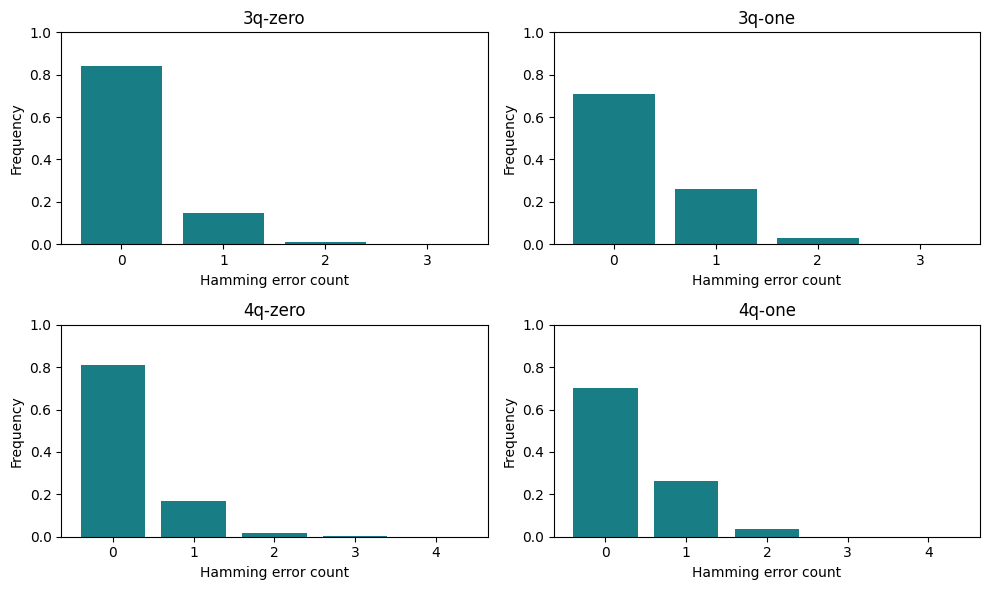

In [5]:
joint = load("joint_error_patterns.json")
display(pd.DataFrame([{"probe": key, **pair} for key, value in joint.items() for pair in value["pairs"]]))
display(load("zero_one_asymmetry.json"))
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, (key, value) in zip(axes.flat, joint.items()):
    histogram = value["metrics"]["number_of_bit_errors_histogram"]
    ax.bar(list(histogram), np.array(list(histogram.values())) / 1024, color="#197d86")
    ax.set(title=key.split("/")[1], xlabel="Hamming error count", ylabel="Frequency", ylim=(0, 1))
fig.tight_layout()
plt.show()


## 5. 最少实验的条件可辨识性与额度决策

单个 4q one-hot 在无噪声时也保留 3! = 6 种不可区分排列；两条非对称基态 0011／0101
可给四个位置提供不同的二位签名，条件性区分 24 种排列，只需 2 个任务。
但前提是各次任务使用同一个已验证物理映射、位序语义明确且信号足够；有噪声时不是确定证明。
当前固定物理布局和收费前编译预览能力未验证，因此下面所有计划 execute=False。


In [6]:
plans = load("candidate_experiment_plan.json")
display(pd.DataFrame([{"candidate": key, "patterns": value["patterns_q0_first"], "tasks": value["tasks"],
    "shots": value["total_shots"], "target_physical_set": value["target_physical_set"],
    "worst_remaining_permutations_noiseless": value["worst_indistinguishable_permutations"],
    "decision": value["decision"]} for key, value in plans.items()]))
assert all(not value["execute"] for value in plans.values())
display(load("mapping_identifiability.json"))
print("NO_NEW_SUBMISSION_RECOMMENDED；金融验收仍INCONCLUSIVE，13/20任务，保留7项。")


,candidate,patterns,tasks,shots,target_physical_set,worst_remaining_permutations_noiseless,decision
0,3q_single_one_hot,[001],1,1024,"[3, 4, 10]",2,NO_NEW_SUBMISSION_RECOMMENDED
1,3q_two_distinct_patterns,"[001, 010]",2,2048,"[3, 4, 10]",1,NO_NEW_SUBMISSION_RECOMMENDED
2,4q_single_one_hot,[0001],1,1024,"[3, 4, 10, 11]",6,NO_NEW_SUBMISSION_RECOMMENDED
3,4q_three_one_hot,"[0001, 0010, 0100]",3,3072,"[3, 4, 10, 11]",1,NO_NEW_SUBMISSION_RECOMMENDED
4,4q_two_asymmetric_patterns,"[0011, 0101]",2,2048,"[3, 4, 10, 11]",1,NO_NEW_SUBMISSION_RECOMMENDED


{'status': 'AMBIGUOUS',
 'reason': 'unknown count serialization and preparation/hardware noise; symmetric probes carry no permutation information',
 'selected_permutation': None,
 'readout_mitigation_applied': False}

NO_NEW_SUBMISSION_RECOMMENDED；金融验收仍INCONCLUSIVE，13/20任务，保留7项。
